# Will this card wheel? Current results (MSH PremierDraft)

A summary of the current models' results on the held-out test set: the last 15% of MSH Premier drafts
chronologically (10,292 drafts, 1.95M passed-card examples, 33% base wheel rate).

Needs `results/MSH.PremierDraft/` (from `scripts/train.py` and `scripts/train_nn.py`) and
`data/features/MSH.PremierDraft/meta.pkl` (from `scripts/build_dataset.py`).

`wheelnet_multiset_plus_target` is the same WheelNet with features-only cards, pretrained on 7 other sets plus
MSH's training drafts (`scripts/train_wheelnet_multiset.py`, see `wheelnet.ipynb` §7). It is the best wheel model.
`wheelnet.ipynb` §8 and `open_lane.ipynb` cover accuracy on the best passed cards and whether the open lane pays.

In [1]:
import json
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").exists())
sys.path.insert(0, str(ROOT / "src"))
from openlane.evaluate import metrics, metrics_by

SET, EVENT = "MSH", "PremierDraft"
OUT = ROOT / "results" / f"{SET}.{EVENT}"
KEYS = ["draft_idx", "pack_number", "pick_number", "card"]

# reference categorical palette, fixed order
BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"
GRAY, INK, MUTED = "#a3a29c", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

In [2]:
df = pl.read_parquet(OUT / "test_predictions.parquet")
nn = pl.read_parquet(OUT / "test_predictions_wheelnet.parquet").drop("wheeled")
df = df.join(nn, on=KEYS, how="inner")
# features-only WheelNet pretrained on 7 other sets + MSH (wheelnet.ipynb §7)
mt = pl.read_parquet(OUT / "test_predictions_wheelnet_multiset_plus_target.parquet").drop("wheeled")
df = df.join(mt, on=KEYS, how="inner")
df = df.with_columns(((pl.col("lgbm_all") + pl.col("wheelnet")) / 2).alias("ensemble"))

meta = pickle.load(open(ROOT / "data" / "features" / f"{SET}.{EVENT}" / "meta.pkl", "rb"))
cards = meta["meta"].with_row_index("card").with_columns(pl.col("card").cast(pl.Int16))
df = df.join(cards.select("card", "name", "rarity"), on="card", how="left")

MODELS = ["prior_by_pick", "alsa_ata_logreg", "card_x_pick_rate", "lgbm_card", "lgbm_card_pack",
          "lgbm_card_signals", "lgbm_all", "wheelnet", "wheelnet_multiset_plus_target", "ensemble"]
res = json.load(open(OUT / "results.json"))
print(f"{df.height:,} test examples, {df['draft_idx'].n_unique():,} drafts, "
      f"wheel rate {df['wheeled'].mean():.3f}")

1,945,092 test examples, 10,292 drafts, wheel rate 0.333


## 1. Headline table

`vs ALSA` is the relative log-loss reduction against the ALSA/ATA logistic baseline, the benchmark from the
project plan. Higher is better.

In [3]:
y = df["wheeled"].to_numpy()
base = metrics(y, df["alsa_ata_logreg"].to_numpy())["logloss"]
rows = []
for m in MODELS:
    r = metrics(y, df[m].to_numpy())
    by_pack = metrics_by(df, m, ["pack_number"])["logloss"].to_list()
    rows.append({"model": m, **r, "vs_alsa": 1 - r["logloss"] / base,
                 **{f"ll_P{k + 1}": v for k, v in enumerate(by_pack)}})
table = pl.DataFrame(rows)
with pl.Config(tbl_rows=20, float_precision=4, tbl_hide_dataframe_shape=True):
    display(table)

model,logloss,brier,auc,ece,vs_alsa,ll_P1,ll_P2,ll_P3
str,f64,f64,f64,f64,f64,f64,f64,f64
"""prior_by_pick""",0.6067,0.2099,0.6389,0.0000,-0.3108,0.6067,0.6067,0.6067
"""alsa_ata_logreg""",0.4629,0.1517,0.8309,0.0073,0.0000,0.4528,0.4658,0.4700
"""card_x_pick_rate""",0.4602,0.1511,0.8328,0.0088,0.0057,0.4503,0.4627,0.4678
"""lgbm_card""",0.4588,0.1506,0.8339,0.0084,0.0088,0.4470,0.4623,0.4671
"""lgbm_card_pack""",0.4397,0.1444,0.8502,0.0076,0.0500,0.4279,0.4431,0.4483
"""lgbm_card_signals""",0.4496,0.1474,0.8418,0.0057,0.0286,0.4461,0.4535,0.4492
"""lgbm_all""",0.4315,0.1414,0.8566,0.0052,0.0677,0.4278,0.4352,0.4316
"""wheelnet""",0.4249,0.1390,0.8618,0.0024,0.0820,0.4241,0.4269,0.4237
"""wheelnet_multiset_plus_target""",0.4188,0.1370,0.8663,0.0030,0.0953,0.4149,0.4223,0.4192


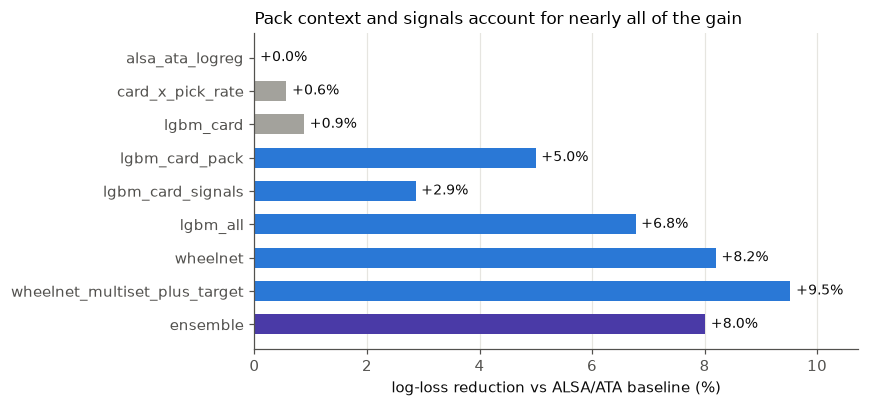

In [4]:
t = table.filter(pl.col("model") != "prior_by_pick")
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [GRAY if m in ("alsa_ata_logreg", "card_x_pick_rate", "lgbm_card") else BLUE
          for m in t["model"]]
colors[-1] = VIOLET  # ensemble
bars = ax.barh(t["model"], t["vs_alsa"] * 100, color=colors, height=0.6)
for b, v in zip(bars, t["vs_alsa"]):
    ax.text(b.get_width() + 0.1, b.get_y() + b.get_height() / 2, f"{v:+.1%}",
            va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlabel("log-loss reduction vs ALSA/ATA baseline (%)")
ax.set_title("Pack context and signals account for nearly all of the gain", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, t["vs_alsa"].max() * 100 + 1.2)
plt.tight_layout()

Card identity is close to used up: the per-card, per-pick lookup only adds +0.6% over ALSA. Pack context
(`lgbm_card_pack`) adds the most. Signals stack on top of it. WheelNet learns from the raw draft history
with no hand-built features and ties `lgbm_all`. Averaging the two gives the best score.

## 2. Where the gain comes from, pick by pick

This is the log-loss improvement over the card-only lookup (`card_x_pick_rate`) at each of the 6 pickable
positions (a pack seen at pick *p* comes back at *p+8*). If signals matter, the gap should grow in later
packs, once earlier rounds have shown what the table is drafting.

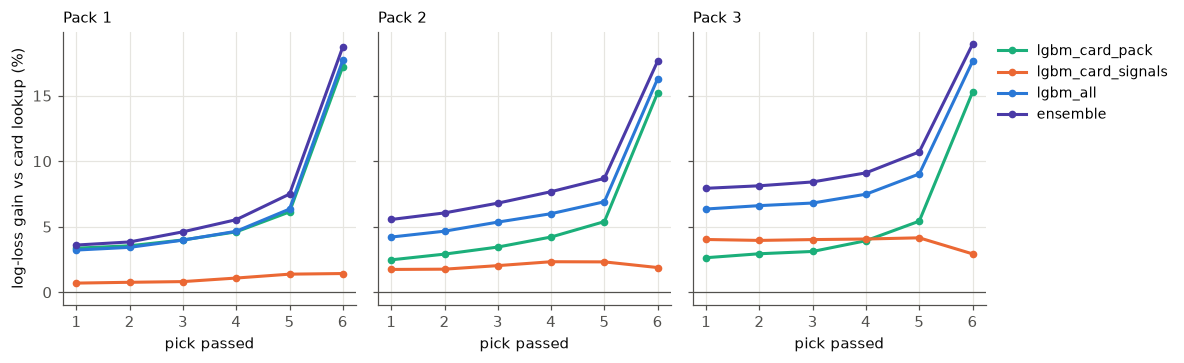

In [5]:
by = {m: metrics_by(df, m, ["pack_number", "pick_number"]) for m in
      ["card_x_pick_rate", "lgbm_card_pack", "lgbm_card_signals", "lgbm_all", "ensemble"]}
ref = by["card_x_pick_rate"]["logloss"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
series = [("lgbm_card_pack", AQUA), ("lgbm_card_signals", ORANGE), ("lgbm_all", BLUE), ("ensemble", VIOLET)]
for pk, ax in enumerate(axes):
    for m, c in series:
        d = by[m].with_columns(gain=1 - pl.col("logloss") / ref).filter(pl.col("pack_number") == pk)
        ax.plot(d["pick_number"] + 1, d["gain"] * 100, marker="o", ms=4, color=c, label=m)
    ax.set_title(f"Pack {pk + 1}", loc="left", fontsize=10)
    ax.set_xlabel("pick passed")
    ax.axhline(0, color=MUTED, lw=0.8)
axes[0].set_ylabel("log-loss gain vs card lookup (%)")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
plt.tight_layout()

In [6]:
# summarized per pack
pl.DataFrame([{"pack": pk + 1, **{m: float(np.mean(1 - by[m].filter(pl.col("pack_number") == pk)["logloss"].to_numpy()
                                            / ref[pk * 6:(pk + 1) * 6]))
                                  for m, _ in series}} for pk in range(3)])

pack,lgbm_card_pack,lgbm_card_signals,lgbm_all,ensemble
i64,f64,f64,f64,f64
1,0.064759,0.010262,0.065541,0.072985
2,0.056078,0.020094,0.072365,0.087345
3,0.055499,0.038564,0.08981,0.105361


The signal-only model's gain is small in pack 1 and grows through packs 2 and 3. Earlier wheels tell you
which colours the table is taking. The spike at pick 6 is the last wheelable pick: that pack comes back
with only one card left. Whether a specific card survives then depends mostly on what else is in the pack,
and the card-only lookup can't see that.

## 3. Calibration

These are reliability curves on the test set (20 equal-width bins). Points on the diagonal are well
calibrated. The top panel plots the *gap* (observed minus predicted) because the raw curves overlap almost
exactly. The bars at the bottom show where the predictions fall.

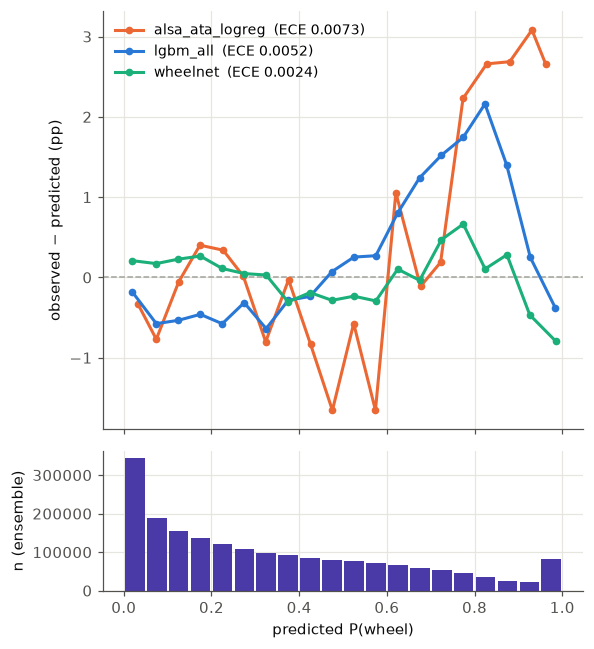

In [7]:
bins = np.linspace(0, 1, 21)
fig, (ax, axh) = plt.subplots(2, 1, figsize=(5.5, 6), sharex=True, height_ratios=[3, 1])
ax.axhline(0, color=GRAY, lw=1, ls="--")
for m, c in [("alsa_ata_logreg", ORANGE), ("lgbm_all", BLUE), ("wheelnet", AQUA)]:
    p = df[m].to_numpy()
    b = np.minimum((p * 20).astype(int), 19)
    n = np.bincount(b, minlength=20)
    ok = n > 500
    conf = np.bincount(b, weights=p, minlength=20)[ok] / n[ok]
    acc = np.bincount(b, weights=y, minlength=20)[ok] / n[ok]
    ece = metrics(y, p)["ece"]
    ax.plot(conf, (acc - conf) * 100, marker="o", ms=4, color=c, label=f"{m}  (ECE {ece:.4f})")
ax.set_ylabel("observed − predicted (pp)")
ax.legend(fontsize=9)
axh.hist(df["ensemble"].to_numpy(), bins=bins, color=VIOLET, rwidth=0.9)
axh.set_ylabel("n (ensemble)")
axh.set_xlabel("predicted P(wheel)")
plt.tight_layout()

## 4. What the GBM uses

This is gain-based feature importance for `lgbm_all`, the top 15 features.
`wheel_cp` is the card's train-set wheel rate at this pick. `n_better` counts the cards in the passed pack
that are usually taken before this one. `resid_prior_card` measures whether this card's colours wheeled more
than expected in earlier rounds, which is the table signal.

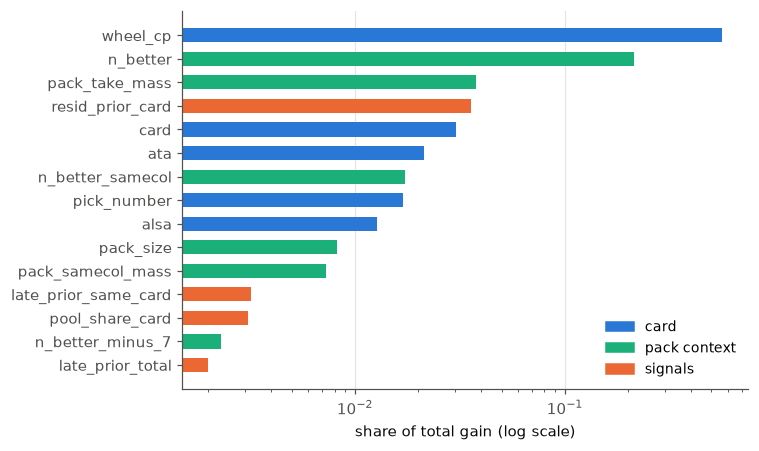

In [8]:
imp = res["importance"]["lgbm_all"]
top = sorted(imp.items(), key=lambda kv: -kv[1])[:15]
groups = {"card": ["wheel_cp", "ata", "alsa", "card", "wheel_c", "pick_number", "take_rate", "rarity"],
          "pack": ["n_better", "pack_take_mass", "n_better_samecol", "pack_size", "pack_samecol_mass",
                   "n_better_minus_7", "my_pick_wheel_cp", "my_pick_samecol"]}
col = lambda f: BLUE if f in groups["card"] else AQUA if f in groups["pack"] else ORANGE
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh([k for k, _ in top], [v for _, v in top], color=[col(k) for k, _ in top], height=0.6)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("share of total gain (log scale)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="card"), Patch(color=AQUA, label="pack context"),
                   Patch(color=ORANGE, label="signals")], loc="lower right", fontsize=9)
plt.tight_layout()

## 5. Breakdown by rarity

This checks whether the gain holds for rares and mythics, where "will it come back?" matters most, or
whether it comes mostly from commons that always wheel.

In [9]:
rows = []
for (r,), g in df.group_by(["rarity"]):
    yy = g["wheeled"].to_numpy()
    if yy.min() == yy.max():
        continue
    a = metrics(yy, g["alsa_ata_logreg"].to_numpy())
    e = metrics(yy, g["ensemble"].to_numpy())
    rows.append({"rarity": r, "n": g.height, "wheel_rate": yy.mean(), "ll_alsa": a["logloss"],
                 "ll_ensemble": e["logloss"], "gain": 1 - e["logloss"] / a["logloss"],
                 "auc_alsa": a["auc"], "auc_ensemble": e["auc"]})
order = {"common": 0, "uncommon": 1, "rare": 2, "mythic": 3}
rar = pl.DataFrame(rows).sort(pl.col("rarity").replace_strict(order, default=9))
with pl.Config(float_precision=4, tbl_hide_dataframe_shape=True):
    display(rar)

rarity,n,wheel_rate,ll_alsa,ll_ensemble,gain,auc_alsa,auc_ensemble
str,i64,f64,f64,f64,f64,f64,f64
"""common""",1253171,0.3479,0.5079,0.4669,0.0807,0.8037,0.8379
"""uncommon""",509216,0.2208,0.4418,0.4070,0.0786,0.7828,0.8195
"""rare""",81548,0.1183,0.3072,0.2849,0.0727,0.7952,0.8319
"""mythic""",8850,0.0703,0.2026,0.1882,0.0714,0.8474,0.8711
"""basic""",92307,0.9721,0.1310,0.1187,0.0941,0.7038,0.7336


The gain holds across rarities. It is 6.5% on rares and 5.4% on mythics, a bit below the 7.3% on commons.
AUC rises for every rarity, so the model is not just scoring commons that always wheel.

## 6. One real pack

Here is a single test pack at pick 1 of pack 1: the ensemble's P(wheel) for each card passed, with what
actually happened. `alsa` is the baseline's prediction, for comparison.

In [10]:
d0 = df.filter((pl.col("pack_number") == 0) & (pl.col("pick_number") == 0))["draft_idx"].unique().sort()[123]
pack = (df.filter((pl.col("draft_idx") == d0) & (pl.col("pack_number") == 0) & (pl.col("pick_number") == 0))
          .select("name", "rarity", pl.col("alsa_ata_logreg").alias("alsa"), "lgbm_all", "wheelnet",
                  "ensemble", pl.col("wheeled").cast(pl.Boolean).alias("came_back"))
          .sort("ensemble", descending=True))
with pl.Config(tbl_rows=20, float_precision=3, tbl_hide_dataframe_shape=True, fmt_str_lengths=40):
    display(pack)

name,rarity,alsa,lgbm_all,wheelnet,ensemble,came_back
str,str,f32,f32,f32,f32,bool
"""Hawkeye's Bow""","""common""",0.763,0.808,0.793,0.800,false
"""Project Deathlok Soldier""","""common""",0.796,0.818,0.776,0.797,false
"""Super Suit""","""common""",0.737,0.690,0.703,0.696,true
"""Los Diablos Missile Base""","""common""",0.532,0.668,0.688,0.678,true
"""Misty Knight, Hero for Hire""","""uncommon""",0.503,0.562,0.609,0.586,false
"""Guerrilla Gorilla""","""common""",0.594,0.542,0.524,0.533,true
"""Roxxon Brutes""","""common""",0.581,0.572,0.480,0.526,true
"""Savage Land Dinosaur""","""common""",0.538,0.490,0.538,0.514,true
"""Thirst for Knowledge""","""uncommon""",0.523,0.502,0.452,0.477,true


## Summary

- The best model, an average of `lgbm_all` and WheelNet, cuts log loss **7.3%** versus the ALSA/ATA baseline
  and raises AUC from 0.831 to 0.859.
- **Pack context** (+5.0%) is the biggest single lever. **Signals** (+2.9% alone) stack with it, and their
  value grows over the draft.
- WheelNet (raw history, no features) ties the GBM and is better calibrated (ECE 0.0018 vs 0.0052).

Next ideas are in the [README](../README.md#next-ideas).